In [ ]:
!pip install statsmodels lightgbm mlforecast shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.7/261.7 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.6/348.6 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 10.3 MB/s eta 0:00:00


# What Is a Blog Post Actually Worth? A Causal Detective Story

*Or: how I asked SHAP a simple question, got a confident wrong answer, and had to learn a little econometrics to fix it.*

**How to read this notebook:** run it top to bottom. Each act adds one idea, runs a little
code, and shows the output right away — the story and the results unfold together.

---

## The question

Every time I publish an article, traffic jumps, fades over a few days, and returns to normal.
So: **how many extra views does publishing an article actually buy me?** I have ~3.7 years of
daily Medium views with a flag for the days an article went out. Let's load it.

In [ ]:
%matplotlib inline
import datetime
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import lightgbm as lgb, shap
from mlforecast import MLForecast

# consistent colors: blue = causal/correct, orange = SHAP/model, red = flag
C_CAUSAL, C_SHAP, C_FLAG, C_GREY = "#185FA5", "#EF9F27", "#C0392B", "#999999"

URL = ("https://raw.githubusercontent.com/marcopeix/time-series-analysis/"
       "refs/heads/master/data/medium_views_published_holidays.csv")
df = pd.read_csv(URL, parse_dates=["ds"]).sort_values("ds").reset_index(drop=True)
df["published"] = df["published"].astype(int)
df["dow"] = df["ds"].dt.dayofweek     # 0 = Mon ... 6 = Sun
df["t"]   = np.arange(len(df))        # linear time index (for the trend)
df.head()

,unique_id,ds,y,published,is_holiday,dow,t
0,0,2020-01-01,1131,0,1,2,0
1,0,2020-01-02,1764,0,0,3,1
2,0,2020-01-03,1699,0,0,4,2
3,0,2020-01-04,1322,0,0,5,3
4,0,2020-01-05,1491,0,0,6,4


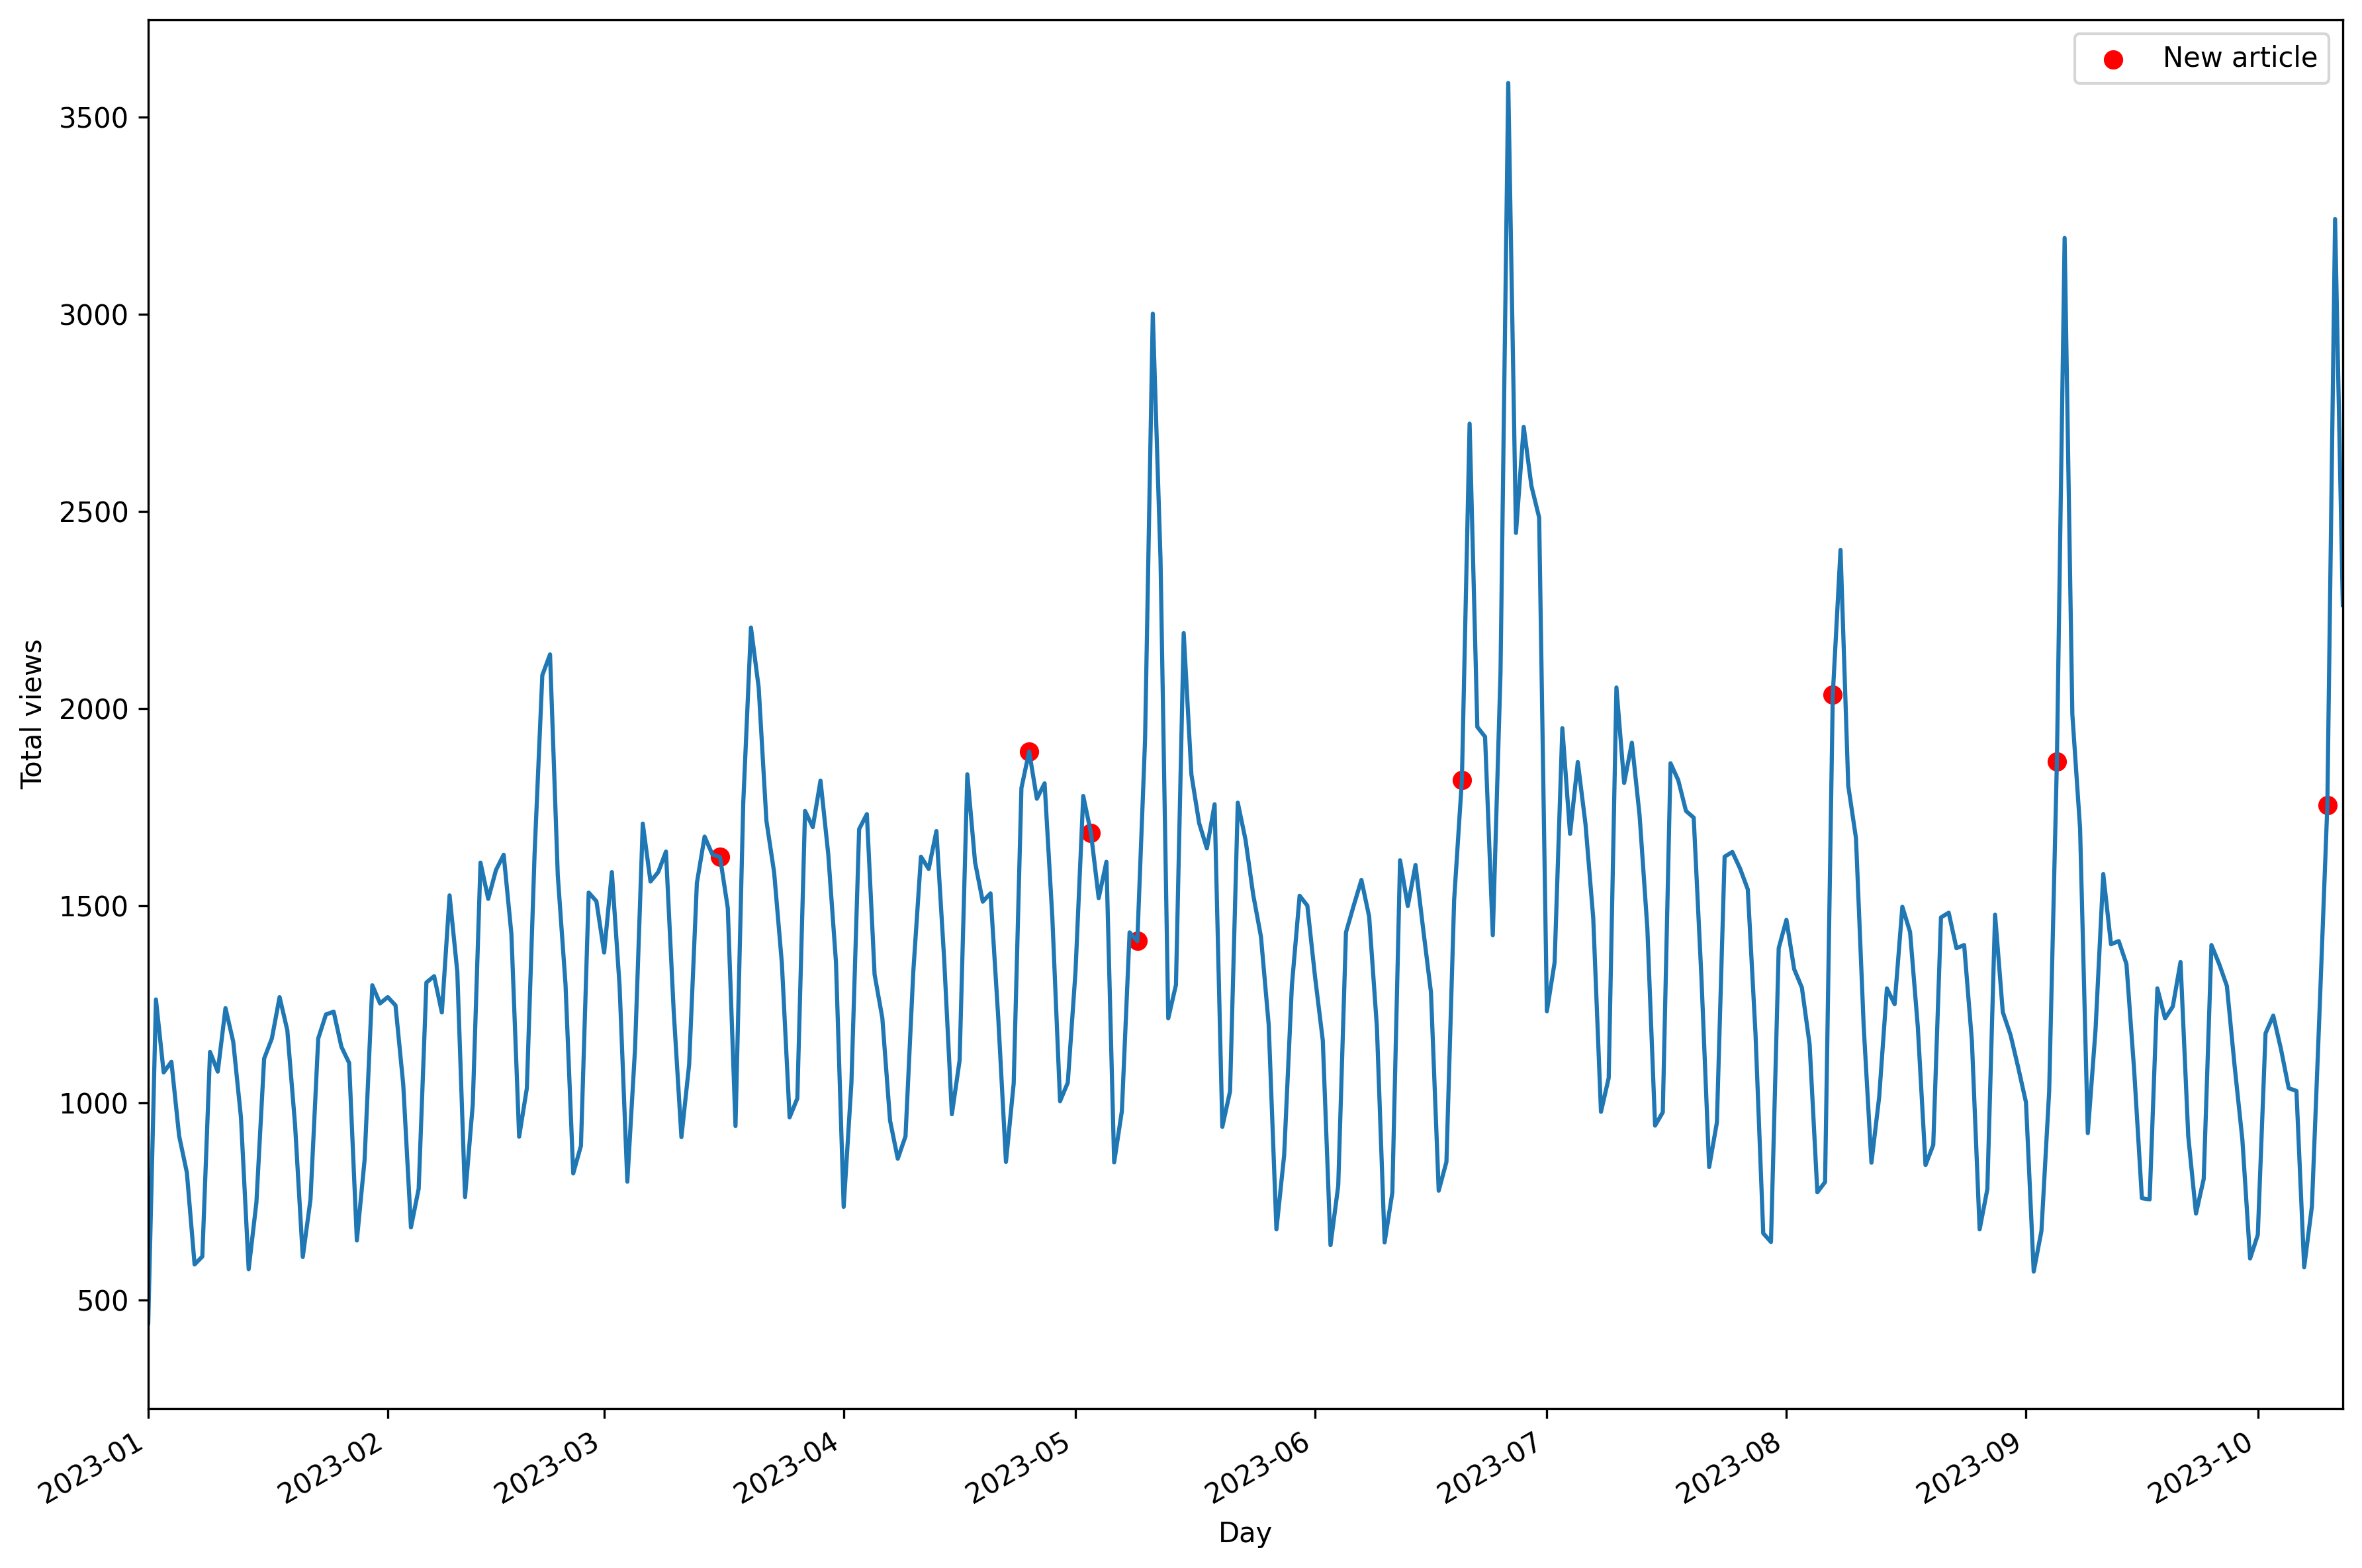

In [ ]:
published_dates = df[df['published'] == 1]

fig, ax = plt.subplots(figsize=(12,8), dpi=300)

ax.plot(df['ds'], df['y'])
ax.scatter(published_dates['ds'], published_dates['y'], marker='o', color='red', label='New article')
ax.set_xlabel('Day')
ax.set_ylabel('Total views')
ax.legend(loc='best')
ax.set_xlim([datetime.date(2023, 1, 1), datetime.date(2023, 10, 12)])

fig.autofmt_xdate()
plt.tight_layout()

## Act I — The shortcut that lied to me

The modern reflex: train a forecaster to predict daily views from its own recent history plus a
`published` flag, then use **SHAP** to read off how much each feature contributes. Whatever SHAP
assigns to `published` is the value of publishing. Let's try it.

In [ ]:
mlf_df = df[["unique_id", "ds", "y", "published", "is_holiday"]].copy()

fcst = MLForecast(
    models={"lgb": lgb.LGBMRegressor(n_estimators=400,
                                     learning_rate=0.03,
                                     num_leaves=31,
                                     verbose=-1)},
    freq="D", lags=[1, 2, 3, 7], date_features=["dayofweek"],
)
prep = fcst.preprocess(mlf_df, static_features=[])   # build lag + calendar features
fcst.fit(mlf_df, static_features=[])

feats = [c for c in prep.columns if c not in ("unique_id", "ds", "y")]
sv = pd.DataFrame(shap.TreeExplainer(fcst.models_["lgb"]).shap_values(prep[feats]),
                  columns=feats, index=prep.index)

importance = sv.abs().mean().sort_values(ascending=False)   # mean |SHAP| per feature
print(importance.round(1).to_string())

lag1          296.5
lag7          112.1
dayofweek      97.7
lag3           29.8
lag2           22.7
is_holiday      3.5
published       2.9


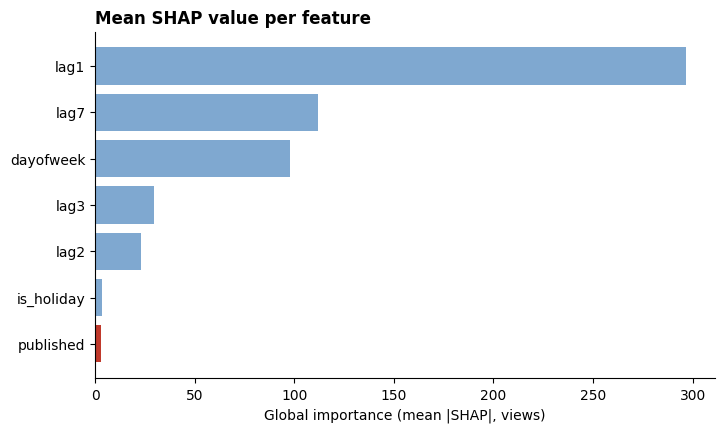

In [ ]:
imp = importance.sort_values()
colors = [C_FLAG if n == "published" else "#7FA8D0" for n in imp.index]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp.index, imp.values, color=colors)
ax.set_xlabel("Global importance (mean |SHAP|, views)")
ax.set_title("Mean SHAP value per feature", fontweight="bold", loc="left")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.show()

**Publishing ranked last.** The one action I take to grow the blog looks like noise, below
yesterday's views, last week's views, and the calendar. But traffic *visibly* jumps when I post —
so either my eyes are lying or SHAP is answering a different question than the one I asked.

> **Theory, briefly — attribution vs. causation.** SHAP explains a *prediction*: given these
> inputs, how much did each push the model's output? That's a fact about the fitted function on
> data that already happened. My question — *what happens to traffic if I publish?* — is about an
> *intervention*. "What is my model using?" and "what happens if I act?" are different questions.

Let's park the mystery and ask the data directly.

## Act II — What am I actually asking?

State the estimand as a **counterfactual**:

- **Factual:** I published on day *t*; views were *Y*.
- **Counterfactual:** same day, but I *didn't* publish; views would have been *Y₀*.
- **Causal effect** = *Y − Y₀*.

The catch: *Y₀ never happens*. We see only one branch. Everything below estimates that missing branch.

> **Theory, briefly — potential outcomes & confounding.** This is the Neyman–Rubin potential-outcomes
> view. The main threat is a **confounder** — a common cause of both posting and traffic. "I post when
> I already have momentum" lifts both, so naively crediting the whole spike to the article overstates
> it. The fix: compare each post against what that same stretch looked like *just before* it.

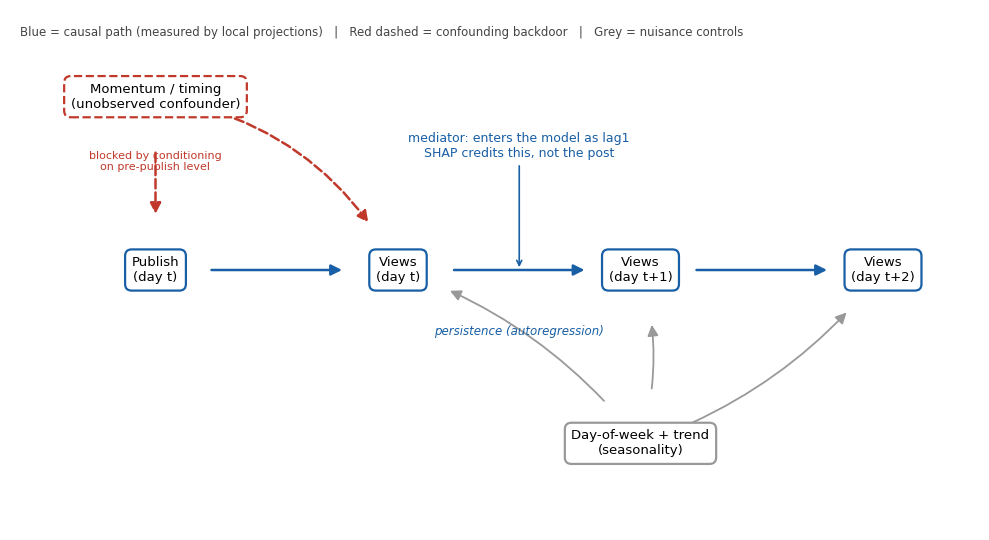

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

# structure declared once; positions are hand-set (time flows left->right)
pos = {"P": (1.5, 3.0), "Y0": (4.0, 3.0), "Y1": (6.5, 3.0), "Y2": (9.0, 3.0),
       "U": (1.5, 5.0), "S": (6.5, 1.0)}
labels = {"P": "Publish\n(day t)", "Y0": "Views\n(day t)", "Y1": "Views\n(day t+1)",
          "Y2": "Views\n(day t+2)", "U": "Momentum / timing\n(unobserved confounder)",
          "S": "Day-of-week + trend\n(seasonality)"}
node_color = {"P": C_CAUSAL, "Y0": C_CAUSAL, "Y1": C_CAUSAL, "Y2": C_CAUSAL,
              "U": C_FLAG, "S": C_GREY}

G = nx.DiGraph()
G.add_nodes_from(pos)
# (u, v, color, linestyle, curvature)
edges = [("P", "Y0", C_CAUSAL, "solid", 0.0),
         ("Y0", "Y1", C_CAUSAL, "solid", 0.0),
         ("Y1", "Y2", C_CAUSAL, "solid", 0.0),        # persistence chain
         ("U", "P", C_FLAG, "dashed", 0.0),
         ("U", "Y0", C_FLAG, "dashed", -0.25),        # confounding backdoor
         ("S", "Y0", C_GREY, "solid", 0.15),
         ("S", "Y1", C_GREY, "solid", 0.15),
         ("S", "Y2", C_GREY, "solid", 0.15)]          # nuisance controls
G.add_edges_from((u, v) for u, v, *_ in edges)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off")

# nodes as boxed labels (bbox gives the rounded box; dashed edge for the confounder)
for n in G:
    ax.text(*pos[n], labels[n], ha="center", va="center", fontsize=9.5, zorder=4,
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec=node_color[n], lw=1.6,
                      ls="--" if n == "U" else "-"))

# draw each edge individually so color / style / curvature can differ
for u, v, color, ls, rad in edges:
    nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], ax=ax,
                           edge_color=color, style=ls, width=1.8 if color != C_GREY else 1.3,
                           arrowsize=16, arrowstyle="-|>",
                           connectionstyle=f"arc3,rad={rad}",
                           node_size=6500, min_source_margin=18, min_target_margin=18)

# the argument-carrying annotations (still plain matplotlib)
ax.annotate("mediator: enters the model as lag1\nSHAP credits this, not the post",
            xy=(5.25, 3.0), xytext=(5.25, 4.3), ha="center", fontsize=9, color=C_CAUSAL,
            arrowprops=dict(arrowstyle="->", color=C_CAUSAL, lw=1.2))
ax.text(5.25, 2.25, "persistence (autoregression)", ha="center",
        fontsize=8.5, style="italic", color=C_CAUSAL)
ax.text(1.5, 4.15, "blocked by conditioning\non pre-publish level",
        ha="center", fontsize=8, color=C_FLAG)
ax.text(0.1, 5.7, "Blue = causal path (measured by local projections)   |   "
        "Red dashed = confounding backdoor   |   Grey = nuisance controls",
        fontsize=8.5, color="#444")
plt.tight_layout(); plt.show()

## Act III — Letting the data reset my assumptions

Two quick checks decide the whole approach: are posts isolated enough to see one article's decay,
and what nuisance structure (seasonality, trend) is in the way?

In [ ]:
post_rows = df.index[df.published == 1].to_numpy()
gaps = pd.Series(post_rows).diff().dropna()
print(f"Posts: {df.published.sum()}   median gap: {gaps.median():.0f} days   "
      f">=3 clear days after: {(gaps >= 3).mean()*100:.0f}%")

print("\nMean views by day of week (0=Mon..6=Sun):")
print(df.groupby("dow")["y"].mean().round(0).to_string())

print("\nPosts by day of week (note the 0s -> no counterfactual for those days):")
print(df.groupby("dow")["published"].sum().to_string())

Posts: 25   median gap: 28 days   >=3 clear days after: 96%

Mean views by day of week (0=Mon..6=Sun):
dow
0    1558.0
1    1572.0
2    1563.0
3    1500.0
4    1297.0
5     974.0
6    1099.0

Posts by day of week (note the 0s -> no counterfactual for those days):
dow
0    6
1    7
2    6
3    2
4    2
5    0
6    2


Median gap of **28 days** with 96% of posts having 3+ clear days after — posts are well isolated,
so a single article's decay is traceable. Weekly seasonality is strong (weekday ≈ 1,560 vs Saturday
≈ 970), so day-of-week must be controlled. And I've **never posted on a Saturday** — remember that;
it's why the "which weekday is best?" question is unanswerable from this data.

Now the picture that changed my mind — an **event study**. Line every post up at day 0 and average
the surrounding days, two ways: *naive* (remove trend + seasonality only) and *corrected* (also
subtract each post's own pre-period, differencing away the "I post when things are good" pedestal).

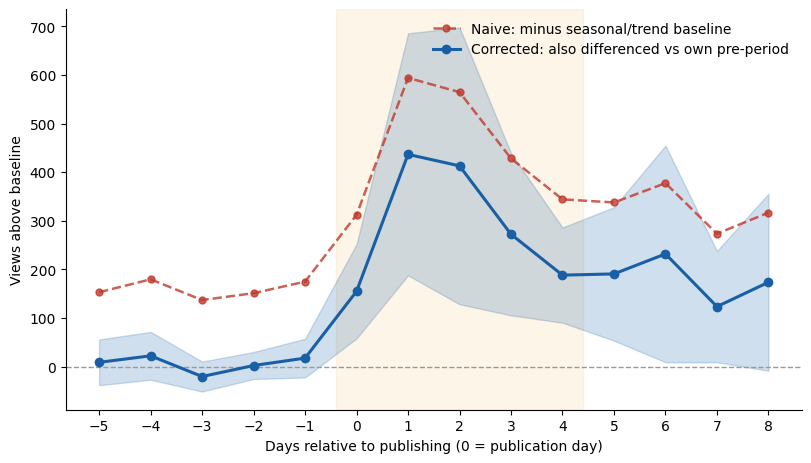

In [ ]:
postset = set(post_rows)
window = {p + h for p in post_rows for h in range(-1, 8)}     # days near a post
quiet = df[~df.index.isin(window)]                            # baseline from quiet days only
base = smf.ols("y ~ C(dow) + t", quiet).fit()
resid = df["y"] - base.predict(df)                            # trend + seasonality removed

offsets = list(range(-5, 9))
def curve(per_event_base):
    rows = {h: [] for h in offsets}
    for p in post_rows:
        b = (np.mean([resid[p + k] for k in (-3, -2, -1) if 0 <= p + k < len(df)])
             if per_event_base else 0.0)
        for h in offsets:
            j = p + h
            if 0 <= j < len(df) and not (h != 0 and j in postset):
                rows[h].append(resid[j] - b)
    m  = {h: np.mean(v) for h, v in rows.items()}
    se = {h: np.std(v, ddof=1) / np.sqrt(len(v)) for h, v in rows.items()}
    return m, se

naive, _      = curve(per_event_base=False)
corr, corr_se = curve(per_event_base=True)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.axhline(0, color=C_GREY, ls="--", lw=1)
ax.axvspan(-0.4, 4.4, color=C_SHAP, alpha=0.10)
yA = [naive[h] for h in offsets]; yB = [corr[h] for h in offsets]
eB = [1.96 * corr_se[h] for h in offsets]
ax.plot(offsets, yA, "o--", color=C_FLAG, lw=1.8, ms=5, alpha=0.8,
        label="Naive: minus seasonal/trend baseline")
ax.fill_between(offsets, np.array(yB) - eB, np.array(yB) + eB, color=C_CAUSAL, alpha=0.20)
ax.plot(offsets, yB, "o-", color=C_CAUSAL, lw=2.2, ms=6,
        label="Corrected: also differenced vs own pre-period")
ax.set_xlabel("Days relative to publishing (0 = publication day)")
ax.set_ylabel("Views above baseline")
ax.set_xticks(offsets); ax.legend(frameon=False)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.show()

Two surprises, both useful:

1. **My "2-day bump" belief was wrong** — the lift peaks the day *after* publishing and fades over
   ~5 days. The data corrected me before I hard-coded a wrong window.
2. **The confounding was real and visible** — the gap between the orange and blue lines *is* the
   pedestal. The corrected line's flat pre-period confirms the differencing worked.

> **Theory, briefly — event study.** With one unit and many time points, an event study is a
> difference-in-differences: each post vs. its own baseline, cancelling anything stable about that
> period. The flat pre-period is the visual analog of a parallel-trends check.

## Act IV — The right tool: local projections

The tool this problem actually calls for comes from macroeconometrics: **local projections**
(Jordà, 2005). Instead of one model of "the effect," fit a *separate regression per horizon*. For
the effect *h* days out, regress views *h* days ahead on today's publish decision — controlling for
seasonality, the trend, and the **pre-publication view level**, which absorbs the pedestal.

In [ ]:
d0 = df.copy()
d0["y_lag1"] = d0["y"].shift(1)     # pre-treatment baseline (yesterday)
d0["y_lag2"] = d0["y"].shift(2)     # pre-treatment baseline (2 days ago)

lp = []
for h in range(0, 8):
    d = d0.copy()
    d["y_h"]   = d["y"].shift(-h)               # outcome h days ahead
    d["dow_h"] = d["dow"].shift(-h)             # its day-of-week
    d["hol_h"] = d["is_holiday"].shift(-h)      # its holiday flag
    # net out any OTHER post landing between t+1 and t+h (avoids contamination)
    d["other"] = (sum((d["published"].shift(-k) for k in range(1, h + 1)),
                      start=pd.Series(0, index=d.index)) if h >= 1 else 0)
    d = d.dropna(subset=["y_h", "y_lag1", "y_lag2", "dow_h"])

    m = smf.ols("y_h ~ published + other + C(dow_h) + hol_h + t + y_lag1 + y_lag2", d) \
           .fit(cov_type="HAC", cov_kwds={"maxlags": max(h, 1)})   # HAC: autocorrelation-robust
    lo, hi = m.conf_int().loc["published"]
    lp.append((h, m.params["published"], lo, hi, m.pvalues["published"]))

causal_by_h = {h: b for h, b, *_ in lp}
print("h    effect     95% CI              p")
for h, b, lo, hi, p in lp:
    print(f"+{h}   {b:7.0f}   [{lo:6.0f}, {hi:6.0f}]   {p:.3f}")
for c in (2, 4, 7):
    print(f"cumulative through day +{c}: {sum(r[1] for r in lp[:c+1]):.0f} views")

h    effect     95% CI              p
+0       151   [    52,    250]   0.003
+1       452   [   209,    695]   0.000
+2       416   [   151,    681]   0.002
+3       292   [   133,    450]   0.000
+4       218   [   121,    315]   0.000
+5       199   [    72,    326]   0.002
+6       204   [     7,    401]   0.042
+7       116   [     5,    226]   0.040
cumulative through day +2: 1020 views
cumulative through day +4: 1530 views
cumulative through day +7: 2048 views


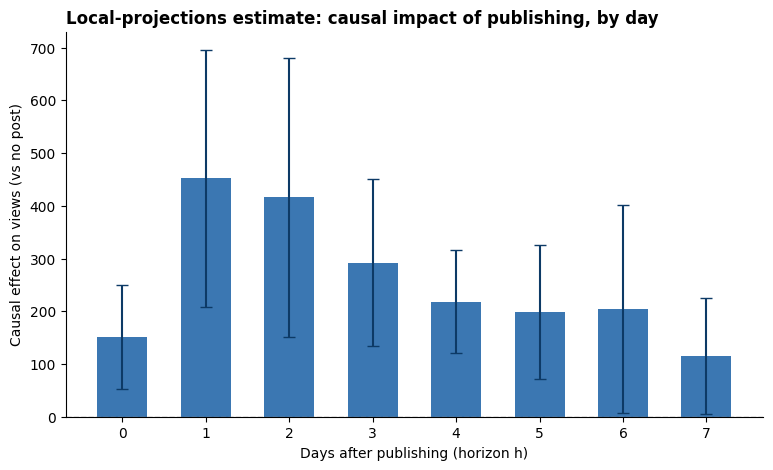

In [ ]:
hs  = [r[0] for r in lp]; bs = [r[1] for r in lp]
err = [[r[1] - r[2] for r in lp], [r[3] - r[1] for r in lp]]
fig, ax = plt.subplots(figsize=(9, 5))
ax.axhline(0, color=C_GREY, ls="--", lw=1)
ax.bar(hs, bs, color=C_CAUSAL, alpha=0.85, width=0.6)
ax.errorbar(hs, bs, yerr=err, fmt="none", ecolor="#0d3a66", elinewidth=1.5, capsize=4)
ax.set_xlabel("Days after publishing (horizon h)")
ax.set_ylabel("Causal effect on views (vs no post)")
ax.set_title("Local-projections estimate: causal impact of publishing, by day",
             fontweight="bold", loc="left")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.show()

There's the answer, with error bars, matching the event-study shape: **a post is worth ~1,500 views
over its first five days, peaking the day after publication.** The pre-period coefficients hover at
zero — publishing doesn't "predict" the days *before* it, the placebo test I'd want to see.

> **Theory, briefly — why this is causal, and HAC.** The `published` coefficient compares posting
> vs. not *holding the controls fixed*; conditioning on the pre-publication level (`y_lag1/2`)
> neutralizes the "post when things are good" confounder, and every control is *pre-treatment* so we
> never adjust for something the post itself caused. Daily traffic is autocorrelated, so **Newey–West
> (HAC)** standard errors keep the intervals honest where ordinary ones would be far too tight.

## Act V — Solving the mystery: why SHAP lost the effect

Back to the crime scene. On the day after a post — the +452 peak — which feature does SHAP thank?

In [ ]:
after = [i for i in prep.index[prep["published"] == 1] + 1
         if i in prep.index and prep.loc[i, "published"] == 0]
print("On the day AFTER a post (the peak), SHAP credit goes to:")
print(f"   published : {sv.loc[after, 'published'].mean():.0f}")
print(f"   lag1      : {sv.loc[after, 'lag1'].mean():.0f}   <-- 'yesterday was high'")

On the day AFTER a post (the peak), SHAP credit goes to:
   published : -1
   lag1      : 290   <-- 'yesterday was high'


The model explains the peak as *"yesterday was high"* and gives the article nothing. But why was
yesterday high? Because I published. SHAP is crediting a **symptom of the cause**.

> **Theory, briefly — mediators.** `lag1` on a post-plus-one day sits on the path
> *post → yesterday's traffic → today's traffic*: it's a **mediator**. Crediting a mediator blocks
> the effect you're trying to see, so the more *persistent* the effect, the *less* credit `published`
> gets — the perverse inversion that made publishing look worthless.

Can I make SHAP tell the truth? Only by handing it the answer: drop the view-lags and give the model
**treatment lags** — was an article published *k* days ago?

In [ ]:
dfB = mlf_df.copy()
for L in range(1, 6):
    dfB[f"pub_lag{L}"] = dfB["published"].shift(L).fillna(0)

fcstB = MLForecast(
    models={"lgb": lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03,
                                     num_leaves=31, verbose=-1)},
    freq="D", lags=[], date_features=["dayofweek"],     # NO target lags
)
prepB = fcstB.preprocess(dfB, static_features=[])
fcstB.fit(dfB, static_features=[])
colsB = [c for c in prepB.columns if c not in ("unique_id", "ds", "y")]
svB = pd.DataFrame(shap.TreeExplainer(fcstB.models_["lgb"]).shap_values(prepB[colsB]),
                   columns=colsB, index=prepB.index)

pub_family = ["published"] + [f"pub_lag{L}" for L in range(1, 6)]
post_pos = prepB.index[prepB["published"] == 1].to_numpy()
shapB_by_h = []
print("day   SHAP credit   (causal)")
for k, feat in enumerate(pub_family):
    rows = [p + k for p in post_pos if (p + k) in prepB.index]
    val = svB.loc[rows, feat].mean(); shapB_by_h.append(val)
    print(f"+{k}     {val:6.0f}       (~{causal_by_h[k]:.0f})")

day   SHAP credit   (causal)
+0        158       (~151)
+1        434       (~452)
+2        428       (~416)
+3        306       (~292)
+4        242       (~218)
+5        222       (~199)


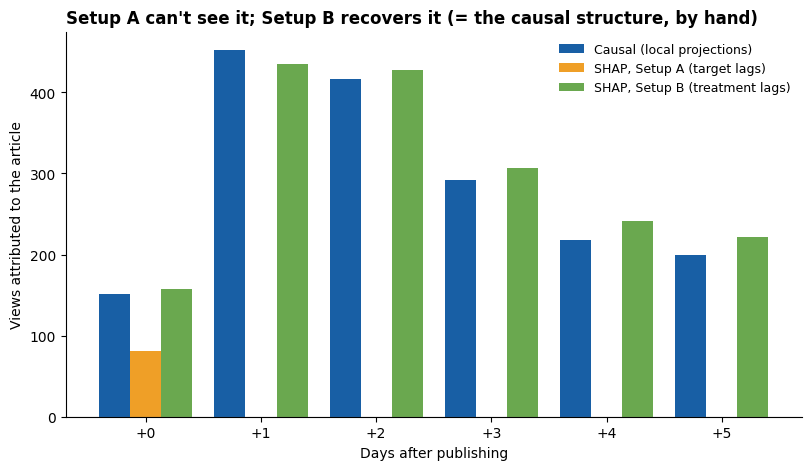

In [ ]:
hs = list(range(6)); causal = [causal_by_h[h] for h in hs]
shapA = [sv.loc[prep["published"] == 1, "published"].mean()] + [0] * 5
x = np.arange(len(hs)); w = 0.27
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.bar(x - w, causal,      w, color=C_CAUSAL,  label="Causal (local projections)")
ax.bar(x,     shapA,       w, color=C_SHAP,    label="SHAP, Setup A (target lags)")
ax.bar(x + w, shapB_by_h,  w, color="#6AA84F", label="SHAP, Setup B (treatment lags)")
ax.axhline(0, color=C_GREY, lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([f"+{h}" for h in hs])
ax.set_xlabel("Days after publishing"); ax.set_ylabel("Views attributed to the article")
ax.set_title("Setup A can't see it; Setup B recovers it (= the causal structure, by hand)",
             fontweight="bold", loc="left")
ax.legend(frameon=False, fontsize=9)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.show()

To make attribution match the causal effect, I had to strip the mediators and encode the treatment's
dynamic structure by hand — i.e. **rebuild the local-projections regression inside the booster.**
SHAP didn't discover the effect; my causal reasoning about which features to include did.

## The moral

> **Feature attribution is downstream of causal assumptions, not a substitute for them.**

SHAP faithfully answers *"what is my model using to predict?"* — useful for debugging models. But it
isn't *"what should I do?"*, and reading it that way ranks the one lever I control (publishing) below
four things I can't act on. The causal question needed a causal tool: a stack of humble regressions,
each honest about its assumptions.

## An honest caveat

The estimate assumes my *timing* of posts is as-good-as-random given trend, seasonality, and the
pre-publication level. The flat pre-period is supporting evidence, not proof. The clean fix is design:
randomize the posting day of the next batch of articles — which would also finally let me answer the
weekday question I can't touch here (no Saturdays = no counterfactual).

---

*See the accompanying post for a fuller narrative and a grouped reading list (Cunningham's
*Mixtape*, Huntington-Klein's *The Effect*, Hernán & Robins for foundations; Jordà 2005 for local
projections; the DoubleML / EconML docs for the ML-causal tools we deliberately didn't need here;
and the SHAP papers plus the "be careful interpreting predictive models" critique).*